<div style="background:linear-gradient(135deg,#0b2b3a 0%,#14506a 45%,#2a9d8f 100%);color:white;padding:34px 30px;border-radius:12px;font-family:'Trebuchet MS','Segoe UI',sans-serif;"><div style="font-size:15px;letter-spacing:3px;color:#bfe9e3">PROYECTO · TALLER II · INFERENCIA · VERSIÓN 2</div><div style="font-size:32px;font-weight:bold;margin:10px 0">🔮 Lencería Lizzy: pronóstico de unidades vendidas con el modelo exportado</div><div style="font-size:18px;color:#d9f4f0">Carga el pipeline guardado, pronostica con una banda de error y avisa cuando la fecha o el tipo están fuera de lo que el modelo conoce</div><hr style="border:0;border-top:1px solid #7fcfc4;margin:18px 0"><div style="font-size:17px"><b>Autora:</b> Lizzy Leyla Baron Barrero · Ing. Informática · UAJMS · Yacuiba<br><b>Modelo:</b> <code>modelo_ventas_v2.joblib</code> (generado por <code>Proyecto_Final_Ventas_Lizzy_v2.ipynb</code>)</div></div>

<div style="border-left:6px solid #b8651b;background:#b8651b14;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#b8651b">⚠️ Qué se puede y qué no se puede afirmar</b><br>El modelo se entrenó con ventas <b>estimadas</b> (reconstruidas de memoria, marcadas con <code>origen = 'estimado'</code>). Estos pronósticos <b>demuestran cómo se usaría el modelo</b>, no predicen con certeza lo que venderá el negocio real. Con ventas registradas por el sistema se reentrena y se vuelve confiable.</div>

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">📘 Qué hace este notebook y cómo ejecutarlo</b><br><b>No entrena nada.</b> Solo carga <code>modelo_ventas_v2.joblib</code> y lo usa. Antes hay que haber ejecutado <code>Proyecto_Final_Ventas_Lizzy_v2.ipynb</code> (genera ese archivo) y dejar los dos notebooks en la misma carpeta. Luego: <i>Kernel → Restart &amp; Run All</i>. Se hacen cuatro demostraciones: <b>(1)</b> una consulta puntual, <b>(2)</b> el pronóstico de una jornada completa, <b>(3)</b> varias fechas desde un CSV editable y <b>(4)</b> qué pasa cuando la fecha se sale del rango de entrenamiento.</div>

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">🧭 Índice</b><br><b>0</b> Configuración · <b>1</b> Carga del modelo y su ficha · <b>2</b> Cómo se hace una predicción · <b>3</b> Consulta puntual · <b>4</b> Pronóstico de una jornada completa · <b>5</b> Pronóstico de varias fechas desde un CSV · <b>6</b> Qué pasa fuera del rango de entrenamiento · <b>7</b> Conclusiones</div>

<div style="background:linear-gradient(90deg,#4a1942,#8e3b7c 70%,#c06c9f);color:white;padding:14px 20px;border-radius:8px;margin-top:22px;font-family:'Trebuchet MS','Segoe UI',sans-serif;font-size:22px;font-weight:bold">🌸 0. Configuración inicial</div>

In [1]:
import warnings, joblib, sklearn, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from IPython.display import display, HTML
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
OUT = Path("salidas_extra_v2"); OUT.mkdir(exist_ok=True)

FUENTE = "font-family:'Trebuchet MS','Segoe UI',sans-serif;"
def nota(titulo, cuerpo, color="#14506a", icono="🔎"):
    display(HTML(f'<div style="border-left:6px solid {color};background:{color}14;padding:12px 16px;margin:8px 0;'
                 f'border-radius:6px;{FUENTE}line-height:1.55"><b style="color:{color}">{icono} {titulo}</b><br>{cuerpo}</div>'))
def mostrar(d, alto=360):
    estilo = ("<style>.tabla{border-collapse:collapse;font-size:12px}.tabla th{position:sticky;top:0;background:#14506a;"
              "color:white;padding:4px 8px}.tabla td{padding:3px 8px;border-bottom:1px solid #d5e4ea;white-space:nowrap}</style>")
    cuerpo = d.to_html(max_rows=None, classes="tabla", border=0, na_rep="", float_format=lambda v: f"{v:.5g}")
    display(HTML(estilo + f'<div style="max-height:{alto}px;overflow:auto;border:2px solid #14506a;border-radius:6px">{cuerpo}</div>'))
COLORES = {"ropa_interior_mujer": "#c06c9f", "cacheteros": "#8e3b7c", "hombre": "#1d4e89", "nino": "#0e7c86",
           "ropa_usada": "#b8651b", "ropa_de_bano": "#2a9d8f", "medias": "#6a3d9a"}

<div style="background:linear-gradient(90deg,#4a1942,#8e3b7c 70%,#c06c9f);color:white;padding:14px 20px;border-radius:8px;margin-top:22px;font-family:'Trebuchet MS','Segoe UI',sans-serif;font-size:22px;font-weight:bold">🌸 1. Carga del modelo y su ficha</div>

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">📘 Qué se hace y por qué</b><br>Se carga el archivo <code>modelo_ventas_v2.joblib</code>. Es un diccionario con el <b>pipeline completo</b> (preprocesamiento + modelo) y todo lo que hace falta para usarlo: variables, tipos y lugares válidos, fechas clave y métricas. Como está guardado el preprocesamiento, <b>no hay que reentrenar ni volver a codificar nada</b>: solo se entrega <i>fecha, lugar y tipo</i>.</div>

In [2]:
def buscar_modelo():
    for c in ["modelo_ventas_v2.joblib", "ciencia_de_datos/modelo_ventas_v2.joblib"]:
        if Path(c).exists(): return Path(c)
    return None
RUTA = buscar_modelo()
if RUTA is None:
    raise FileNotFoundError("No se encontró modelo_ventas_v2.joblib. Ejecutar primero Proyecto_Final_Ventas_Lizzy_v2.ipynb en esta carpeta.")
M = joblib.load(RUTA)
PIPE, FEATS, TIPOS, LUGARES, DIAS = M["pipeline"], M["variables"], M["tipos"], M["lugares"], M["dias_semana"]
F_INI, F_FIN = [pd.Timestamp(x) for x in M["rango_entrenamiento"]]
F_CALOR = pd.Timestamp(M["fecha_calor"]); INICIO = {k: pd.Timestamp(v) for k, v in M["inicio_tipo"].items()}
RMSE_CV, HIST = M["metricas_cv"]["RMSE"], M["historial"]
VISTOS = {tuple(x) for x in M.get("lugar_dia_vistos", [])}

print(f"Modelo cargado de: {RUTA.resolve()}")
if M["version_sklearn"] != sklearn.__version__:
    nota("Versión distinta de scikit-learn", f"El modelo se guardó con scikit-learn <b>{M['version_sklearn']}</b> y aquí hay <b>{sklearn.__version__}</b>. Puede funcionar, pero lo seguro es usar la misma versión.", "#b8651b", "⚠️")
ficha = pd.DataFrame([
    ("Algoritmo elegido", M["nombre_modelo"]), ("Hiperparámetros", str(M["hiperparametros"])),
    ("Variables de entrada", ", ".join(FEATS)), ("Lo que predice", "unidades vendidas por día, lugar y tipo"),
    ("Tipos de prenda", ", ".join(TIPOS)), ("Lugares", ", ".join(LUGARES)),
    ("Rango de entrenamiento", f"{F_INI.date()} a {F_FIN.date()}"), ("Inicio del indicador de calor", str(F_CALOR.date())),
    ("Datos de origen", f"{M['datos_fuente']['lineas']} líneas, {M['datos_fuente']['pedidos']} pedidos, {M['datos_fuente']['dias_distintos']} días (exportados el {M['datos_fuente']['fecha_exportacion'][:10]})"),
    ("Días de prueba", ", ".join(M["dias_prueba"])), ("Versión de scikit-learn", M["version_sklearn"])], columns=["Dato", "Valor"])
mostrar(ficha, 380)

Modelo cargado de: /home/touken/Lencer-a_Lizzy/ciencia_de_datos/modelo_ventas_v2.joblib


,Dato,Valor
0,Algoritmo elegido,Gradient Boosting
1,Hiperparámetros,"{'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 200}"
2,Variables de entrada,"lugar_venta, dia_semana, tipo, mes, semana_iso, calor"
3,Lo que predice,"unidades vendidas por día, lugar y tipo"
4,Tipos de prenda,"cacheteros, hombre, medias, nino, ropa_de_bano, ropa_interior_mujer, ropa_usada"
5,Lugares,"feria_barrio_nuevo, mercado_lourdes"
6,Rango de entrenamiento,2026-08-03 a 2026-11-17
7,Inicio del indicador de calor,2026-09-22
8,Datos de origen,"375 líneas, 249 pedidos, 29 días (exportados el 2026-11-22)"
9,Días de prueba,"2026-08-12, 2026-08-13, 2026-08-17, 2026-08-21, 2026-10-06, 2026-11-10"


<div style="border-left:6px solid #0e7c86;background:#0e7c8614;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#0e7c86">🔎 Cómo leer esto</b><br>Es la «ficha técnica» del modelo: con qué datos se entrenó, qué variables necesita y en qué rango de fechas fue entrenado. Esta última fila importa: <b>fuera de ese rango el modelo extrapola</b> y su pronóstico es menos confiable (se ve en la sección 6).</div>

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">📘 Qué se hace y por qué</b><br>Las <b>métricas guardadas</b> dicen qué tan bueno es el modelo. Se comparan con la <b>referencia</b> (predecir siempre el promedio), que es lo que se haría sin modelo. Es lo primero que conviene mirar antes de confiar en un pronóstico.</div>

,Métrica,Modelo en prueba,Referencia en prueba
0,RMSE (unidades),1.753,2.872
1,MAE (unidades),1.187,2.096
2,R²,0.627,-0


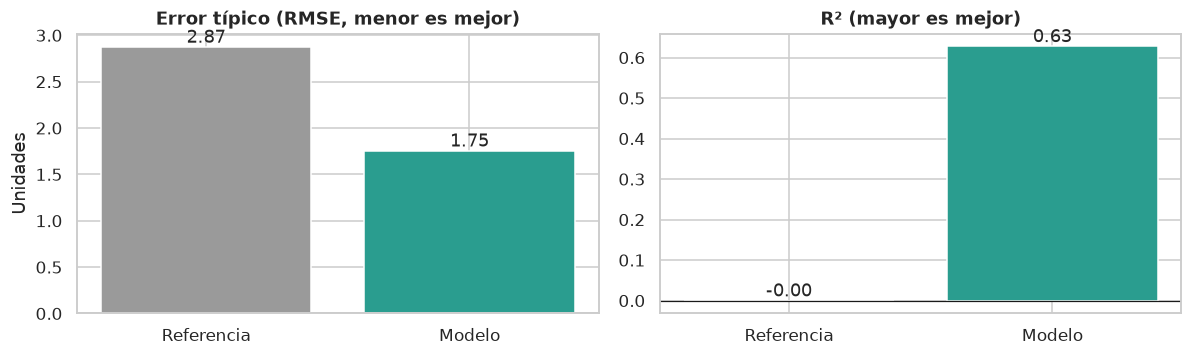

In [3]:
mt, mr = M["metricas_test"], M["metricas_referencia_test"]
tabla_m = pd.DataFrame({"Métrica": ["RMSE (unidades)", "MAE (unidades)", "R²"], "Modelo en prueba": [mt["RMSE"], mt["MAE"], mt["R²"]],
                        "Referencia en prueba": [mr["RMSE"], mr["MAE"], mr["R²"]]})
mostrar(tabla_m.round(3), 160)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].bar(["Referencia", "Modelo"], [mr["RMSE"], mt["RMSE"]], color=["#9a9a9a", "#2a9d8f"]); ax[0].set_title("Error típico (RMSE, menor es mejor)"); ax[0].set_ylabel("Unidades")
for k, v in enumerate([mr["RMSE"], mt["RMSE"]]): ax[0].text(k, v, f"{v:.2f}", ha="center", va="bottom")
ax[1].bar(["Referencia", "Modelo"], [mr["R²"], mt["R²"]], color=["#9a9a9a", "#2a9d8f"]); ax[1].set_title("R² (mayor es mejor)"); ax[1].axhline(0, color="k", lw=0.8)
for k, v in enumerate([mr["R²"], mt["R²"]]): ax[1].text(k, v, f"{v:.2f}", ha="center", va="bottom")
plt.tight_layout(); plt.show()
nota("Lectura automática", f"En días nunca vistos, el modelo se equivoca en promedio <b>{mt['MAE']:.2f}</b> unidades (MAE) y su error típico es <b>{mt['RMSE']:.2f}</b>, "
     f"un <b>{1 - mt['RMSE'] / mr['RMSE']:.0%}</b> menos que la referencia ({mr['RMSE']:.2f}). Explica el <b>{mt['R²']:.0%}</b> de la variación de las ventas. "
     "Son pocos días de prueba, así que las cifras son orientativas.")

<div style="border-left:6px solid #0e7c86;background:#0e7c8614;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#0e7c86">🔎 Cómo leer esto</b><br>La barra gris es lo que se obtendría sin modelo, prediciendo siempre el promedio. Si la barra verde de RMSE es más baja, el modelo aporta; si la de R² es más alta, explica más. Con ese error típico se construye la <b>banda de error</b> de las predicciones de las siguientes secciones.</div>

In [4]:
tabla_ini = pd.DataFrame({"Tipo": list(INICIO), "Primera venta": [d.date() for d in INICIO.values()],
                          "Promedio por jornada en el entrenamiento": [HIST["promedio_tipo"][t] for t in INICIO],
                          "Máximo en una jornada": [HIST["maximo_tipo"][t] for t in INICIO]}).sort_values("Primera venta")
mostrar(tabla_ini, 260)

,Tipo,Primera venta,Promedio por jornada en el entrenamiento,Máximo en una jornada
1,hombre,2026-08-03,1.724,4
2,medias,2026-08-03,2.069,7
3,nino,2026-08-03,0.448,2
5,ropa_interior_mujer,2026-08-03,4.276,9
0,cacheteros,2026-08-05,1.222,7
6,ropa_usada,2026-09-08,3.455,6
4,ropa_de_bano,2026-09-22,8,12


<div style="border-left:6px solid #0e7c86;background:#0e7c8614;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#0e7c86">🔎 Cómo leer esto</b><br>Desde cuándo se vendía cada tipo y cuánto vendía en el entrenamiento. Sirve de comparación: si un pronóstico supera mucho el <b>máximo</b> de su tipo, conviene desconfiar. La ropa de baño y la ropa usada empiezan en septiembre: antes de esa fecha el modelo no sabe nada de ellas.</div>

<div style="background:linear-gradient(90deg,#4a1942,#8e3b7c 70%,#c06c9f);color:white;padding:14px 20px;border-radius:8px;margin-top:22px;font-family:'Trebuchet MS','Segoe UI',sans-serif;font-size:22px;font-weight:bold">🌸 2. Cómo se hace una predicción</div>

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">📘 Qué se hace y por qué</b><br>La función <code>predecir()</code> recibe una tabla con tres columnas: <b>fecha, lugar y tipo</b>. A partir de la fecha calcula el día de la semana, el mes, la semana ISO y el indicador de calor; llama al pipeline guardado y devuelve: <ul><li><b>unidades_pred</b>: la predicción (nunca negativa).</li><li><b>minimo_aprox / maximo_aprox</b>: una <b>banda orientativa</b> de ± el RMSE de la validación cruzada (no es un intervalo estadístico, solo da idea del margen de error).</li><li><b>promedio_historico</b> y <b>maximo_historico</b>: lo que ese tipo vendía en el entrenamiento, para comparar.</li><li><b>aviso</b> y <b>confianza</b>: advierten cuando la fecha cae fuera del rango, el tipo aún no se vendía o el lugar nunca vendió ese día de la semana.</li></ul></div>

In [5]:
def predecir(consultas):
    q = consultas.copy(); q["fecha"] = pd.to_datetime(q["fecha"])
    malos_l, malos_t = set(q["lugar_venta"]) - set(LUGARES), set(q["tipo"]) - set(TIPOS)
    if malos_l or malos_t:
        raise ValueError(f"Valores no válidos. Lugares permitidos: {LUGARES}. Tipos permitidos: {TIPOS}. Recibidos: {sorted(malos_l | malos_t)}")
    dia = q["fecha"].dt.dayofweek.map(dict(enumerate(DIAS)))
    X = pd.DataFrame({"lugar_venta": q["lugar_venta"], "dia_semana": dia, "tipo": q["tipo"], "mes": q["fecha"].dt.month,
                      "semana_iso": q["fecha"].dt.isocalendar().week.astype(int), "calor": (q["fecha"] >= F_CALOR).astype(int)})[FEATS]
    p = np.clip(PIPE.predict(X), 0, None)
    out = q[["fecha", "lugar_venta", "tipo"]].copy()
    out["unidades_pred"] = p.round(1)
    out["minimo_aprox"] = np.clip(p - RMSE_CV, 0, None).round(1); out["maximo_aprox"] = (p + RMSE_CV).round(1)
    out["promedio_historico"] = out["tipo"].map(HIST["promedio_tipo"]); out["maximo_historico"] = out["tipo"].map(HIST["maximo_tipo"])
    avisos = []
    for f, l, t, d in zip(q["fecha"], q["lugar_venta"], q["tipo"], dia):
        a = []
        if f > F_FIN: a.append("fecha posterior al entrenamiento")
        if f < F_INI: a.append("fecha anterior al entrenamiento")
        if f < INICIO[t]: a.append("el tipo aún no se vendía")
        if VISTOS and (l, d) not in VISTOS: a.append(f"{l} nunca vendió un {d}")
        avisos.append("; ".join(a))
    out["aviso"] = avisos; out["confianza"] = np.where(out["aviso"] == "", "normal", "baja")
    return out.reset_index(drop=True)

<div style="border-left:6px solid #0e7c86;background:#0e7c8614;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#0e7c86">🔎 Cómo leer esto</b><br>Es la única función que se necesita para usar el modelo. Si se pide un lugar o tipo que el modelo no conoce, falla con un mensaje que lista los valores permitidos, en lugar de dar un número sin sentido. La columna <b>confianza</b> vale «baja» cada vez que hay un aviso.</div>

<div style="background:linear-gradient(90deg,#4a1942,#8e3b7c 70%,#c06c9f);color:white;padding:14px 20px;border-radius:8px;margin-top:22px;font-family:'Trebuchet MS','Segoe UI',sans-serif;font-size:22px;font-weight:bold">🌸 3. Consulta puntual</div>

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">📘 Qué se hace y por qué</b><br>La pregunta más simple: <i>«¿cuántas unidades de este tipo se venderán tal día en tal lugar?»</i>. La gráfica pone la predicción (con su banda de error) junto al <b>promedio</b> y al <b>máximo</b> que ese tipo tuvo en el entrenamiento, para ver si el pronóstico es razonable.</div>

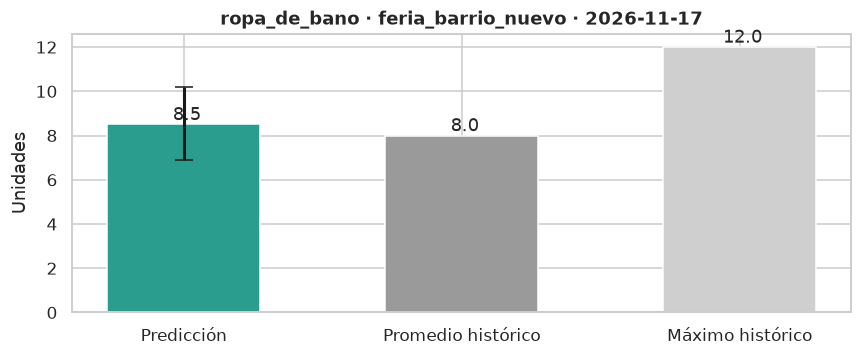

In [6]:
def consulta(fecha, lugar, tipo):
    r = predecir(pd.DataFrame({"fecha": [fecha], "lugar_venta": [lugar], "tipo": [tipo]})).iloc[0]
    fig, ax = plt.subplots(figsize=(8, 3.4))
    vals = [r["unidades_pred"], r["promedio_historico"], r["maximo_historico"]]
    ax.bar(["Predicción", "Promedio histórico", "Máximo histórico"], vals, color=["#2a9d8f", "#9a9a9a", "#cfcfcf"], width=0.55)
    ax.errorbar([0], [r["unidades_pred"]], yerr=[[r["unidades_pred"] - r["minimo_aprox"]], [r["maximo_aprox"] - r["unidades_pred"]]], color="k", capsize=6, lw=2)
    for k, v in enumerate(vals): ax.text(k, v, f" {v:.1f}", va="bottom", ha="center")
    ax.set_ylabel("Unidades"); ax.set_title(f"{tipo} · {lugar} · {pd.Timestamp(fecha).date()}")
    plt.tight_layout(); plt.show()
    extra = f" <b>Aviso:</b> {r['aviso']} (confianza {r['confianza']})." if r["aviso"] else " Sin avisos: la fecha, el tipo y el lugar están dentro de lo que el modelo conoce."
    nota("Resultado", f"Se esperan unas <b>{r['unidades_pred']:.1f}</b> unidades (banda aproximada de {r['minimo_aprox']:.1f} a {r['maximo_aprox']:.1f}). "
         f"En el entrenamiento ese tipo vendía en promedio {r['promedio_historico']:.1f} por jornada y como máximo {int(r['maximo_historico'])}." + extra,
         "#0b6e4f" if not r["aviso"] else "#b8651b", "✅" if not r["aviso"] else "⚠️")
    return r
_ = consulta("2026-11-17", "feria_barrio_nuevo", "ropa_de_bano")

<div style="border-left:6px solid #0e7c86;background:#0e7c8614;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#0e7c86">🔎 Cómo leer esto</b><br>La <b>barra verde</b> es lo que predice el modelo y la <b>línea negra</b> su margen de error aproximado. Si la barra verde queda cerca de la gris (promedio histórico), el modelo espera un día normal; si se acerca a la barra clara (máximo histórico), espera un día excepcional. Esta consulta usa una fecha dentro del rango de entrenamiento, por eso no lleva aviso.</div>

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">📘 Qué se hace y por qué</b><br>Un <b>formulario</b> para probar cualquier combinación sin escribir código (necesita <code>ipywidgets</code>; si no está instalado, se omite sin afectar el resto).</div>

In [8]:
try:
    import ipywidgets as w
    f_fecha = w.DatePicker(description="Fecha", value=pd.Timestamp("2026-11-24").date())
    f_lugar = w.Dropdown(options=LUGARES, description="Lugar")
    f_tipo = w.Dropdown(options=TIPOS, description="Tipo")
    f_btn = w.Button(description="Pronosticar", button_style="success"); f_out = w.Output()
    def _click(_):
        with f_out:
            f_out.clear_output(wait=True)
            if f_fecha.value is None: print("Elige una fecha."); return
            consulta(str(f_fecha.value), f_lugar.value, f_tipo.value)
    f_btn.on_click(_click)
    display(w.VBox([f_fecha, f_lugar, f_tipo, f_btn, f_out]))
except ImportError:
    nota("Formulario omitido", "No está instalado <code>ipywidgets</code>. Las demás secciones funcionan igual; para el formulario: <code>pip install ipywidgets</code>.", "#b8651b", "ℹ️")

<div style="border-left:6px solid #0e7c86;background:#0e7c8614;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#0e7c86">🔎 Cómo leer esto</b><br>Elige fecha, lugar y tipo y pulsa «Pronosticar»: aparece la misma gráfica y el mismo resultado de la consulta puntual. Sirve para mostrar el modelo en vivo durante la defensa. Prueba una fecha de diciembre para ver el aviso de extrapolación.</div>

<div style="background:linear-gradient(90deg,#4a1942,#8e3b7c 70%,#c06c9f);color:white;padding:14px 20px;border-radius:8px;margin-top:22px;font-family:'Trebuchet MS','Segoe UI',sans-serif;font-size:22px;font-weight:bold">🌸 4. Pronóstico de una jornada completa</div>

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">📘 Qué se hace y por qué</b><br>Lo más útil para el negocio: <i>«si mañana voy a la feria, ¿cuántas prendas de cada tipo llevo?»</i>. Se pronostican <b>todos los tipos</b> de un mismo día y lugar. A la izquierda, la predicción de cada tipo con su banda de error y, con un rombo, lo que ese tipo vendía en promedio; a la derecha, <b>qué parte del total</b> se espera de cada tipo.</div>

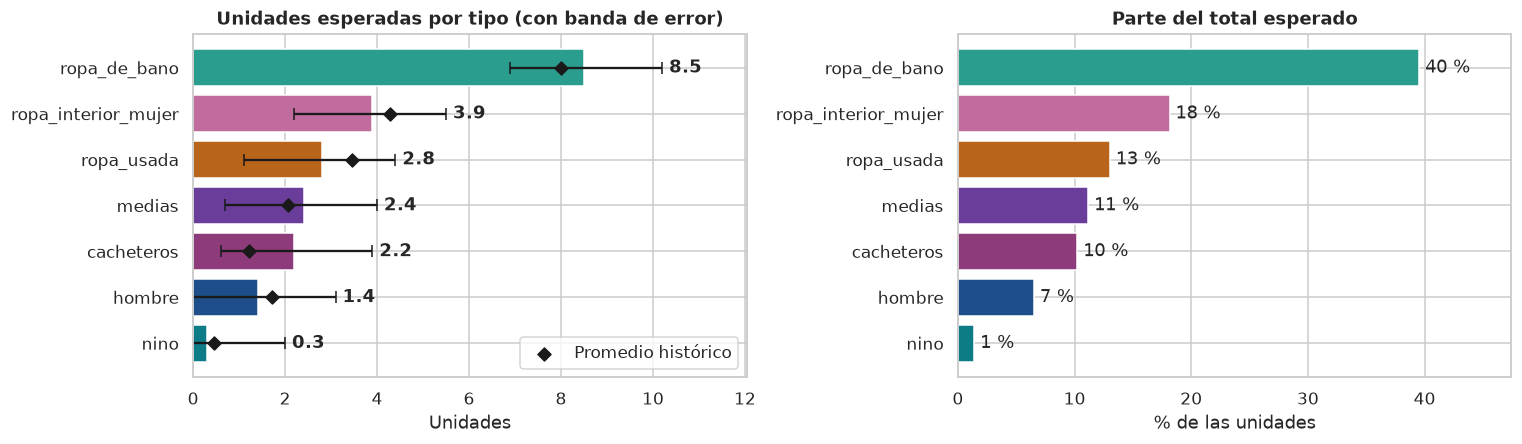

,fecha,lugar_venta,tipo,unidades_pred,minimo_aprox,maximo_aprox,promedio_historico,maximo_historico,aviso,confianza
0,2026-11-24,feria_barrio_nuevo,ropa_de_bano,8.5,6.9,10.2,8,12,fecha posterior al entrenamiento,baja
1,2026-11-24,feria_barrio_nuevo,ropa_interior_mujer,3.9,2.2,5.5,4.276,9,fecha posterior al entrenamiento,baja
2,2026-11-24,feria_barrio_nuevo,ropa_usada,2.8,1.1,4.4,3.455,6,fecha posterior al entrenamiento,baja
3,2026-11-24,feria_barrio_nuevo,medias,2.4,0.7,4,2.069,7,fecha posterior al entrenamiento,baja
4,2026-11-24,feria_barrio_nuevo,cacheteros,2.2,0.6,3.9,1.222,7,fecha posterior al entrenamiento,baja
5,2026-11-24,feria_barrio_nuevo,hombre,1.4,0,3.1,1.724,4,fecha posterior al entrenamiento,baja
6,2026-11-24,feria_barrio_nuevo,nino,0.3,0,2,0.448,2,fecha posterior al entrenamiento,baja


In [9]:
def jornada(fecha, lugar):
    tabla = predecir(pd.DataFrame({"fecha": [fecha] * len(TIPOS), "lugar_venta": [lugar] * len(TIPOS), "tipo": TIPOS}))
    tabla = tabla.sort_values("unidades_pred", ascending=False).reset_index(drop=True)
    activos = tabla[tabla["aviso"].str.contains("aún no se vendía") == False]
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.2)); t = tabla.iloc[::-1]
    ax[0].barh(t["tipo"], t["unidades_pred"], xerr=[t["unidades_pred"] - t["minimo_aprox"], t["maximo_aprox"] - t["unidades_pred"]],
               color=[COLORES[x] for x in t["tipo"]], capsize=4)
    ax[0].scatter(t["promedio_historico"], t["tipo"], marker="D", color="k", zorder=5, label="Promedio histórico"); ax[0].legend(loc="lower right")
    for k, (v, mx) in enumerate(zip(t["unidades_pred"], t["maximo_aprox"])): ax[0].text(mx + 0.15, k, f"{v:.1f}", va="center", fontweight="bold")
    ax[0].set_xlim(0, max(t["maximo_aprox"].max(), t["promedio_historico"].max()) * 1.18)
    ax[0].set_title("Unidades esperadas por tipo (con banda de error)"); ax[0].set_xlabel("Unidades")
    total = tabla["unidades_pred"].sum(); pct = (t["unidades_pred"] / total * 100) if total > 0 else t["unidades_pred"] * 0
    ax[1].barh(t["tipo"], pct, color=[COLORES[x] for x in t["tipo"]])
    for k, v in enumerate(pct): ax[1].text(v, k, f" {v:.0f} %", va="center")
    ax[1].set_title("Parte del total esperado"); ax[1].set_xlabel("% de las unidades"); ax[1].set_xlim(0, max(pct.max() * 1.2, 10))
    plt.tight_layout(); plt.show()
    tip = float(activos["promedio_historico"].sum())
    nota("Resultado", f"Para el <b>{pd.Timestamp(fecha).date()}</b> en <b>{lugar}</b> se esperan unas <b>{total:.0f} prendas</b> en total. El tipo con más ventas esperadas es <b>{tabla.loc[0, 'tipo']}</b> "
         f"({tabla.loc[0, 'unidades_pred']:.1f}). Una jornada típica del entrenamiento sumaba unas {tip:.0f} prendas." +
         (f" <b>Avisos:</b> {'; '.join(sorted(set(a for a in tabla['aviso'] if a)))}." if tabla["aviso"].str.len().sum() else ""))
    return tabla
tabla_j = jornada("2026-11-24", "feria_barrio_nuevo")
mostrar(tabla_j.assign(fecha=tabla_j["fecha"].dt.date), 280)

<div style="border-left:6px solid #0e7c86;background:#0e7c8614;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#0e7c86">🔎 Cómo leer esto</b><br><b>Izquierda:</b> cada barra es la predicción para un tipo; la línea negra es el margen de error aproximado y el <b>rombo</b> marca lo que ese tipo vendía en promedio. Una barra mucho más larga que su rombo indica un día mejor que lo habitual. <b>Derecha:</b> cómo se reparte el total entre los tipos; es la guía para decidir <b>cuánto llevar de cada cosa</b>. La tabla de abajo trae todos los números, incluida la columna de aviso.</div>

<div style="background:linear-gradient(90deg,#4a1942,#8e3b7c 70%,#c06c9f);color:white;padding:14px 20px;border-radius:8px;margin-top:22px;font-family:'Trebuchet MS','Segoe UI',sans-serif;font-size:22px;font-weight:bold">🌸 5. Pronóstico de varias fechas desde un CSV</div>

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">📘 Qué se hace y por qué</b><br>Para pronosticar muchas fechas a la vez, se prepara un CSV con tres columnas (<code>fecha, lugar_venta, tipo</code>). Si no existe, el notebook crea una <b>plantilla</b> en <code>salidas_extra_v2/plantilla_pronostico_v2.csv</code> con tres martes en Barrio Nuevo; <b>puedes editarla</b> con tus propias fechas y volver a ejecutar la celda. El resultado se guarda en <code>resultado_pronostico_v2.csv</code>.</div>

In [10]:
PLANTILLA = OUT / "plantilla_pronostico_v2.csv"
if not PLANTILLA.exists():
    base = pd.DataFrame([(f, "feria_barrio_nuevo", t) for f in ["2026-11-24", "2026-12-01", "2026-12-08"] for t in TIPOS], columns=["fecha", "lugar_venta", "tipo"])
    base.to_csv(PLANTILLA, index=False); print(f"Plantilla creada: {PLANTILLA}")
consultas = pd.read_csv(PLANTILLA)
res = predecir(consultas)
res.to_csv(OUT / "resultado_pronostico_v2.csv", index=False, encoding="utf-8-sig")
print(f"{len(res)} consultas leídas de {PLANTILLA.name}; resultado guardado en salidas_extra_v2/resultado_pronostico_v2.csv")
mostrar(res.assign(fecha=res["fecha"].dt.date), 330)

21 consultas leídas de plantilla_pronostico_v2.csv; resultado guardado en salidas_extra_v2/resultado_pronostico_v2.csv


,fecha,lugar_venta,tipo,unidades_pred,minimo_aprox,maximo_aprox,promedio_historico,maximo_historico,aviso,confianza
0,2026-11-24,feria_barrio_nuevo,cacheteros,2.2,0.6,3.9,1.222,7,fecha posterior al entrenamiento,baja
1,2026-11-24,feria_barrio_nuevo,hombre,1.4,0,3.1,1.724,4,fecha posterior al entrenamiento,baja
2,2026-11-24,feria_barrio_nuevo,medias,2.4,0.7,4,2.069,7,fecha posterior al entrenamiento,baja
3,2026-11-24,feria_barrio_nuevo,nino,0.3,0,2,0.448,2,fecha posterior al entrenamiento,baja
4,2026-11-24,feria_barrio_nuevo,ropa_de_bano,8.5,6.9,10.2,8,12,fecha posterior al entrenamiento,baja
5,2026-11-24,feria_barrio_nuevo,ropa_interior_mujer,3.9,2.2,5.5,4.276,9,fecha posterior al entrenamiento,baja
6,2026-11-24,feria_barrio_nuevo,ropa_usada,2.8,1.1,4.4,3.455,6,fecha posterior al entrenamiento,baja
7,2026-12-01,feria_barrio_nuevo,cacheteros,2.2,0.6,3.9,1.222,7,fecha posterior al entrenamiento,baja
8,2026-12-01,feria_barrio_nuevo,hombre,1.4,0,3.1,1.724,4,fecha posterior al entrenamiento,baja
9,2026-12-01,feria_barrio_nuevo,medias,2.4,0.7,4,2.069,7,fecha posterior al entrenamiento,baja


<div style="border-left:6px solid #0e7c86;background:#0e7c8614;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#0e7c86">🔎 Cómo leer esto</b><br>Cada fila de la tabla es una consulta con su predicción, su banda y su aviso. La columna <b>aviso</b> aparece cuando el modelo está extrapolando; esas filas tienen <b>confianza baja</b> y conviene tomarlas como una orientación, no como un dato.</div>

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">📘 Qué se hace y por qué</b><br>Dos gráficas para <b>leer los resultados de golpe</b>: un mapa de calor con las unidades esperadas por tipo y fecha, y los totales por fecha (en rosado cuando hay avisos).</div>

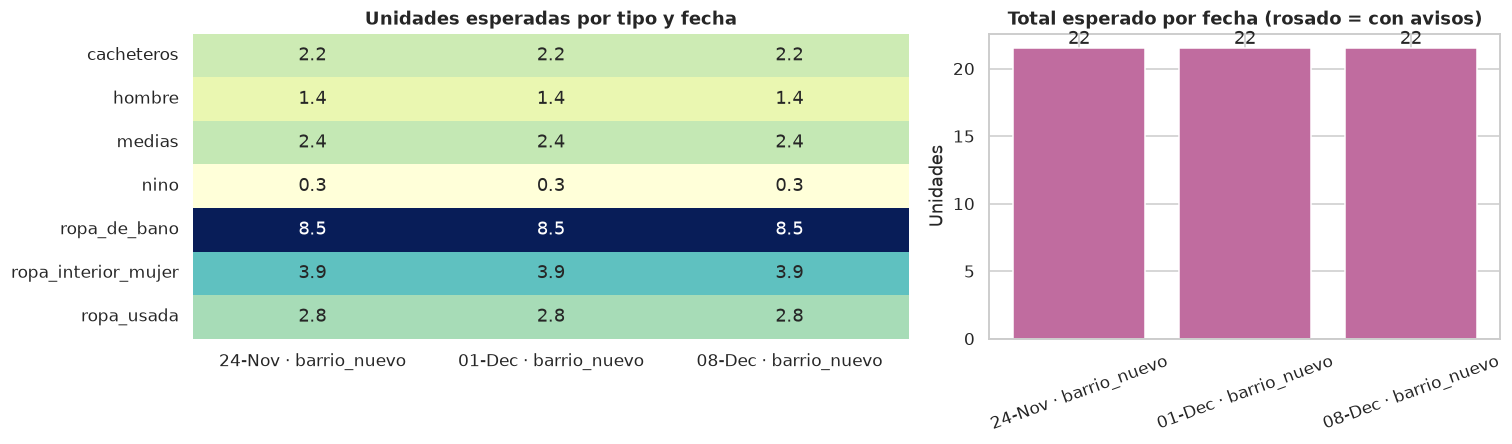

In [11]:
res["f"] = res["fecha"].dt.strftime("%d-%b") + " · " + res["lugar_venta"].str.replace("mercado_", "").str.replace("feria_", "")
piv = res.pivot_table(index="tipo", columns="f", values="unidades_pred", aggfunc="sum", sort=False)
tot = res.groupby("f", sort=False).agg(total=("unidades_pred", "sum"), avisos=("aviso", lambda s: (s != "").any()))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
sns.heatmap(piv, annot=True, fmt=".1f", cmap="YlGnBu", ax=ax[0], cbar=False); ax[0].set_title("Unidades esperadas por tipo y fecha"); ax[0].set_ylabel(""); ax[0].set_xlabel("")
ax[1].bar(tot.index, tot["total"], color=["#c06c9f" if a else "#2a9d8f" for a in tot["avisos"]])
for k, v in enumerate(tot["total"]): ax[1].text(k, v, f"{v:.0f}", ha="center", va="bottom")
ax[1].set_title("Total esperado por fecha (rosado = con avisos)"); ax[1].set_ylabel("Unidades"); ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()
nota("Lectura automática", f"Se consultaron <b>{res['f'].nunique()}</b> fechas; el total esperado va de <b>{tot['total'].min():.0f}</b> a <b>{tot['total'].max():.0f}</b> prendas. "
     f"<b>{int((res['aviso'] != '').sum())}</b> de {len(res)} consultas llevan aviso.")

<div style="border-left:6px solid #0e7c86;background:#0e7c8614;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#0e7c86">🔎 Cómo leer esto</b><br>En el mapa, los colores más oscuros son más unidades. Si <b>todas las fechas</b> muestran números casi idénticos, es una señal de que el modelo no distingue entre ellas, normalmente porque están fuera del rango en que se entrenó (siguiente sección). Las barras rosadas son totales de fechas con avisos.</div>

<div style="background:linear-gradient(90deg,#4a1942,#8e3b7c 70%,#c06c9f);color:white;padding:14px 20px;border-radius:8px;margin-top:22px;font-family:'Trebuchet MS','Segoe UI',sans-serif;font-size:22px;font-weight:bold">🌸 6. Qué pasa fuera del rango de entrenamiento</div>

<div style="border-left:6px solid #1d4e89;background:#1d4e8914;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#1d4e89">📘 Qué se hace y por qué</b><br>Es la limitación más importante del modelo y conviene verla en una gráfica. Se pronostica el total de <b>cada martes en Barrio Nuevo</b>, desde septiembre hasta fines de diciembre. La zona gris es <b>posterior al último día de entrenamiento</b>: el modelo ya no conoce esas fechas y, al ser un modelo de árboles, tiende a <b>repetir el último patrón</b> en lugar de continuar una tendencia.</div>

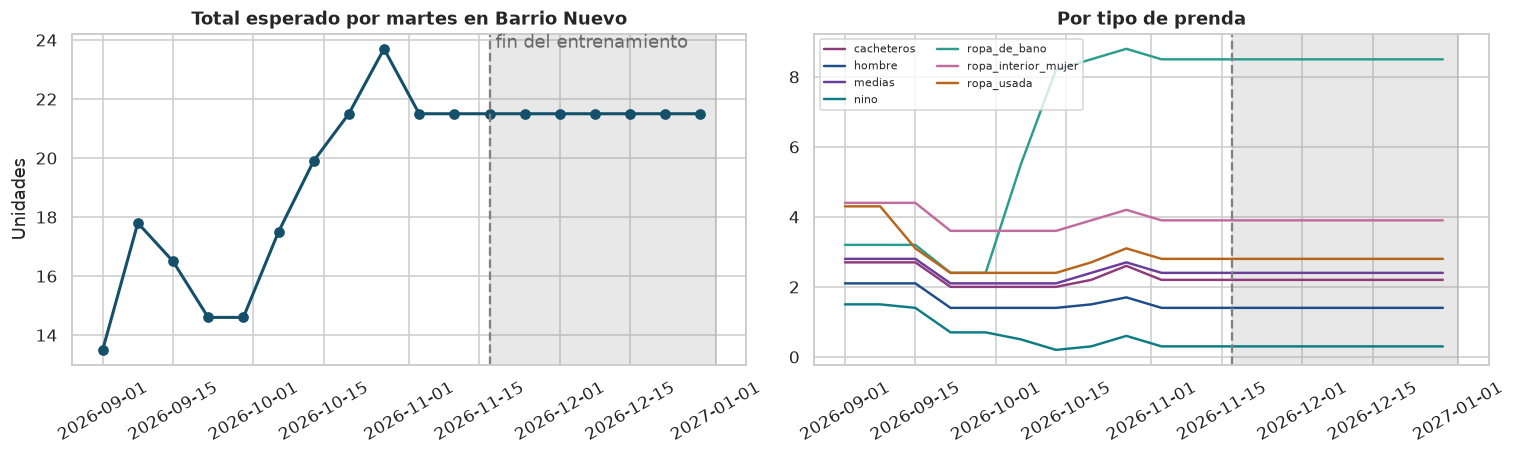

In [12]:
martes = pd.date_range("2026-09-01", "2026-12-29", freq="W-TUE")
cons = pd.DataFrame([(f, "feria_barrio_nuevo", t) for f in martes for t in TIPOS], columns=["fecha", "lugar_venta", "tipo"])
sp = predecir(cons)
activo = sp[sp["aviso"].str.contains("aún no se vendía") == False]
serie = activo.groupby("fecha")["unidades_pred"].sum()
por_tipo = sp.pivot_table(index="fecha", columns="tipo", values="unidades_pred")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
ax[0].plot(serie.index, serie.values, "o-", color="#14506a", lw=2); ax[0].axvspan(F_FIN, serie.index.max() + pd.Timedelta(days=3), color="gray", alpha=0.18)
ax[0].axvline(F_FIN, color="gray", ls="--"); ax[0].text(F_FIN, ax[0].get_ylim()[1], " fin del entrenamiento", va="top", color="dimgray")
ax[0].set_title("Total esperado por martes en Barrio Nuevo"); ax[0].set_ylabel("Unidades"); ax[0].tick_params(axis="x", rotation=30)
for t in TIPOS: ax[1].plot(por_tipo.index, por_tipo[t], "-", color=COLORES[t], label=t, lw=1.6)
ax[1].axvspan(F_FIN, por_tipo.index.max() + pd.Timedelta(days=3), color="gray", alpha=0.18); ax[1].axvline(F_FIN, color="gray", ls="--")
ax[1].set_title("Por tipo de prenda"); ax[1].legend(fontsize=7, ncol=2); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()
despues = serie[serie.index > F_FIN]
nota("Lectura automática", f"Tras el fin del entrenamiento (<b>{F_FIN.date()}</b>) hay {len(despues)} martes pronosticados con valores entre <b>{despues.min():.1f}</b> y <b>{despues.max():.1f}</b> prendas "
     f"({'prácticamente el mismo valor: el modelo repite el último patrón' if despues.max() - despues.min() < 1 else 'con poca variación: el modelo apenas distingue estas fechas'}). "
     "Una variación real de las ventas en diciembre (fiestas, calor) <b>no</b> aparece en estos números.", "#b8651b", "⚠️")

<div style="border-left:6px solid #0e7c86;background:#0e7c8614;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#0e7c86">🔎 Cómo leer esto</b><br>A la izquierda de la línea punteada, cada punto es un martes <b>que el modelo conoce</b> y la curva sigue la evolución aprendida. En la <b>zona gris</b> la curva se aplana: el modelo no puede inventar una tendencia que nunca vio. Es lo que el notebook avisa con la columna «aviso». Para pronosticar diciembre habría que <b>reentrenar con ventas de diciembre</b>. Además, si el año cambiara a enero, el mes y la semana «reiniciarían» y el modelo los confundiría con agosto: otra razón para reentrenar y no extrapolar.</div>

<div style="background:linear-gradient(90deg,#4a1942,#8e3b7c 70%,#c06c9f);color:white;padding:14px 20px;border-radius:8px;margin-top:22px;font-family:'Trebuchet MS','Segoe UI',sans-serif;font-size:22px;font-weight:bold">🌸 7. Conclusiones</div>

In [13]:
nota("Conclusiones", f"<ul><li>El notebook <b>carga el modelo sin reentrenar</b> y pronostica con solo <i>fecha, lugar y tipo</i>.</li>"
     f"<li>Cada predicción lleva una <b>banda de error</b> (± {RMSE_CV:.2f} unidades) y se compara con el <b>promedio y el máximo histórico</b> de su tipo.</li>"
     f"<li>Las columnas <b>aviso</b> y <b>confianza</b> advierten cuando la fecha cae fuera del rango ({F_INI.date()} a {F_FIN.date()}), el tipo aún no se vendía o el lugar nunca vendió ese día.</li>"
     f"<li>Los pronósticos se pueden hacer de una consulta, de una jornada completa o de un CSV con muchas fechas, y se guardan en <code>salidas_extra_v2/</code>.</li></ul>", "#0b6e4f", "✅")

<div style="border-left:6px solid #b8651b;background:#b8651b14;padding:12px 16px;margin:8px 0;border-radius:6px;font-family:'Trebuchet MS','Segoe UI',sans-serif;line-height:1.55"><b style="color:#b8651b">⚠️ Recordatorio de honestidad</b><br>Los datos de entrenamiento son <b>estimados</b> (reconstruidos con reglas). Este notebook demuestra el <b>flujo de uso</b> del modelo, no una predicción confiable del negocio real. Con ventas registradas por el sistema, se reentrena el modelo y se vuelve a ejecutar este notebook sin cambiar nada.</div>